**Pipeline 1:** Data Acquisition & Directory Verification (Roboflow API)

In [1]:
!pip install -q roboflow imagehash scikit-learn seaborn

import os
import random
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
import imagehash
from tqdm.auto import tqdm

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device aktif: {device}")
if torch.cuda.is_available():
    print(f"Tipe GPU    : {torch.cuda.get_device_name(0)}")

Device aktif: cuda
Tipe GPU    : Tesla T4


In [2]:
from roboflow import Roboflow

ROBOFLOW_API_KEY = "FEMBOY_KAWAI KAWAI KAWAI"
WORKSPACE_ID     = "data-fyp-1"
PROJECT_ID       = "oil-palm-fruit-zohnc"
DATASET_VERSION  = 2

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_ID).project(PROJECT_ID)
version = project.version(DATASET_VERSION)
dataset = version.download("folder")

DATA_DIR = Path(dataset.location)
print(f"\nDataset berhasil diunduh ke: {DATA_DIR}")

splits = ["train", "valid", "test"]
for split in splits:
    split_path = DATA_DIR / split
    if split_path.exists():
        classes = sorted([d.name for d in split_path.iterdir() if d.is_dir()])
        total_imgs = sum(len(list((split_path / c).glob("*.*"))) for c in classes)
        print(f"Folder '{split:<5}' -> {total_imgs:>4} gambar | Kelas: {classes}")
    else:
        print(f"PERINGATAN: Folder '{split}' tidak ditemukan!")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Oil-palm-fruit--2 in folder:: 100%|██████████| 4744/4744 [00:01<00:00, 3049.52it/s]



Dataset berhasil diunduh ke: /content/Oil-palm-fruit--2
Folder 'train' -> 2364 gambar | Kelas: ['Overripe', 'Ripe', 'Underripe', 'Unripe']
Folder 'valid' -> 1419 gambar | Kelas: ['Overripe', 'Ripe', 'Underripe', 'Unripe']
Folder 'test ' ->  944 gambar | Kelas: ['Overripe', 'Ripe', 'Underripe', 'Unripe']


**Pipeline 2:** Exploratory Data Analysis (EDA)

Total keseluruhan gambar valid: 4727 gambar


split,train,valid,test,Total,Proporsi (%)
class,,,,,
Unripe,353,192,137,682,14.43
Underripe,741,406,298,1445,30.57
Ripe,749,479,285,1513,32.01
Overripe,521,342,224,1087,23.00


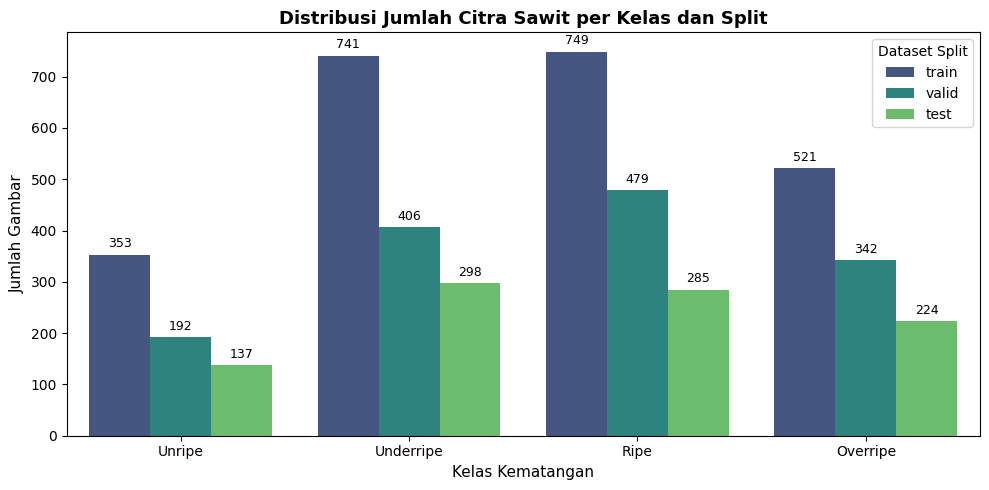


Bobot Kelas untuk Loss Function (Urutan Alfabetik ImageFolder):
  - Overripe  : 1.1344
  - Ripe      : 0.7891
  - Underripe : 0.7976
  - Unripe    : 1.6742


In [3]:
LOGICAL_ORDER = ["Unripe", "Underripe", "Ripe", "Overripe"]
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []
for split in splits:
    split_dir = DATA_DIR / split
    for class_dir in split_dir.iterdir():
        if class_dir.is_dir():
            for img_path in class_dir.iterdir():
                if img_path.suffix.lower() in VALID_EXTS:
                    records.append({
                        "split": split,
                        "class": class_dir.name,
                        "filepath": str(img_path)
                    })

df_meta = pd.DataFrame(records)
print(f"Total keseluruhan gambar valid: {len(df_meta)} gambar")

count_table = pd.crosstab(df_meta["class"], df_meta["split"])[splits]

ordered_classes = [c for c in LOGICAL_ORDER if c in count_table.index]
if len(ordered_classes) == len(count_table.index):
    count_table = count_table.loc[ordered_classes]

count_table["Total"] = count_table.sum(axis=1)
count_table["Proporsi (%)"] = (count_table["Total"] / count_table["Total"].sum() * 100).round(2)
display(count_table)

plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df_meta,
    x="class",
    hue="split",
    order=ordered_classes if ordered_classes else None,
    hue_order=splits,
    palette="viridis"
)
plt.title("Distribusi Jumlah Citra Sawit per Kelas dan Split", fontsize=13, fontweight="bold")
plt.xlabel("Kelas Kematangan", fontsize=11)
plt.ylabel("Jumlah Gambar", fontsize=11)
plt.legend(title="Dataset Split")

for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.tight_layout()
plt.show()

train_df = df_meta[df_meta["split"] == "train"]
alphabetical_classes = sorted(train_df["class"].unique())
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(alphabetical_classes),
    y=train_df["class"].values
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nBobot Kelas untuk Loss Function (Urutan Alfabetik ImageFolder):")
for cls_name, w in zip(alphabetical_classes, class_weights):
    print(f"  - {cls_name:<10}: {w:.4f}")

In [4]:
corrupt_files = []
md5_records = []
phash_records = []

print("Memindai integritas dan duplikasi gambar...")
for idx, row in tqdm(df_meta.iterrows(), total=len(df_meta)):
    fpath = row["filepath"]
    try:
        with Image.open(fpath) as img:
            img.verify()  # Cek kerusakan struktur file
        with Image.open(fpath) as img:
            img_rgb = img.convert("RGB")
            # MD5 untuk duplikat byte-persis
            file_md5 = hashlib.md5(img_rgb.tobytes()).hexdigest()
            # pHash untuk kemiripan visual sangat tinggi
            file_phash = str(imagehash.phash(img_rgb))

            md5_records.append((file_md5, row["split"], row["class"], fpath))
            phash_records.append((file_phash, row["split"], row["class"], fpath))
    except (UnidentifiedImageError, OSError, Exception) as e:
        corrupt_files.append((fpath, str(e)))

print(f"\n1. Jumlah file rusak (corrupt)           : {len(corrupt_files)}")

df_md5 = pd.DataFrame(md5_records, columns=["md5", "split", "class", "filepath"])
exact_dups = df_md5[df_md5.duplicated("md5", keep=False)]
print(f"2. Jumlah gambar duplikat persis (MD5)   : {len(exact_dups)} file ({exact_dups['md5'].nunique()} grup)")

# Cek kebocoran lintas split (Train vs Test)
cross_split_leak = exact_dups.groupby("md5")["split"].nunique()
leaked_hashes = cross_split_leak[cross_split_leak > 1]
print(f"3. Grup duplikat lintas split (Train/Val/Test): {len(leaked_hashes)} grup")

if len(leaked_hashes) > 0:
    print("   [Info] Ditemukan gambar identik di lebih dari satu split. Anda bisa mencatat temuan ini di bab EDA.")

Memindai integritas dan duplikasi gambar...


  0%|          | 0/4727 [00:00<?, ?it/s]


1. Jumlah file rusak (corrupt)           : 0
2. Jumlah gambar duplikat persis (MD5)   : 0 file (0 grup)
3. Grup duplikat lintas split (Train/Val/Test): 0 grup


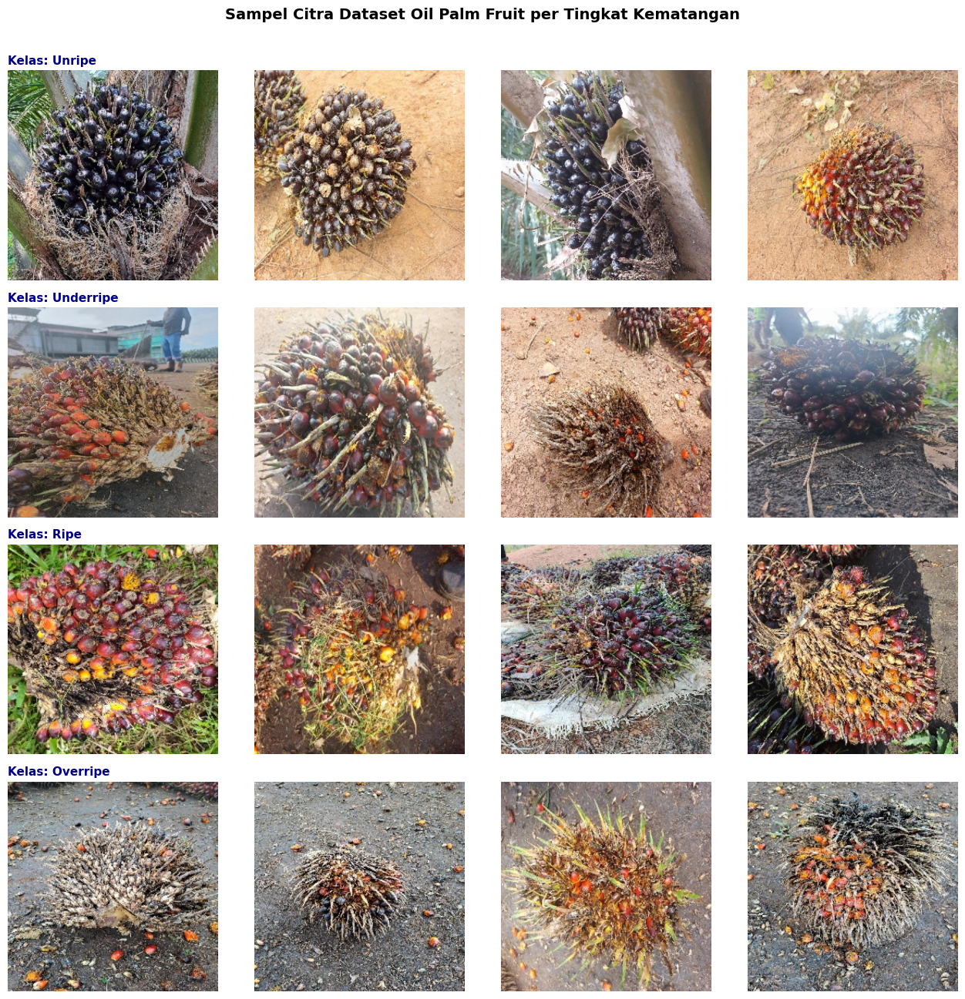

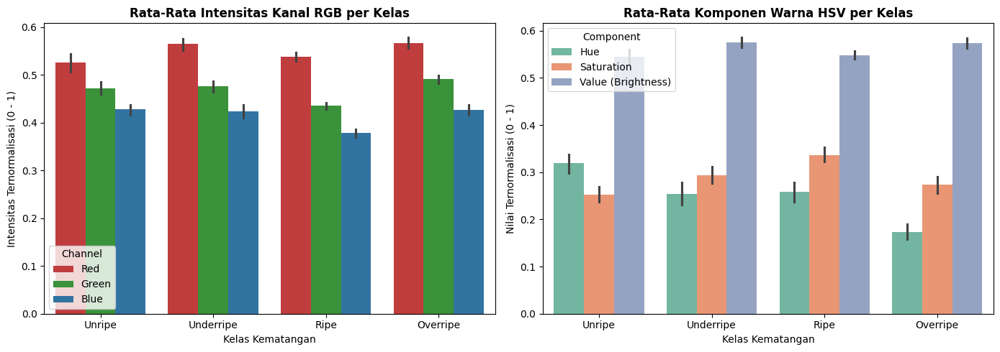

In [7]:
display_classes = ordered_classes if ordered_classes else alphabetical_classes
fig, axes = plt.subplots(len(display_classes), 4, figsize=(13, 3.2 * len(display_classes)))

for row_idx, cls_name in enumerate(display_classes):
    samples = train_df[train_df["class"] == cls_name].sample(n=4, random_state=SEED)
    for col_idx, (_, sample_row) in enumerate(samples.iterrows()):
        img = Image.open(sample_row["filepath"]).convert("RGB")
        ax = axes[row_idx, col_idx]
        ax.imshow(img)
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(f"Kelas: {cls_name}", fontsize=11, fontweight="bold", loc="left", color="darkblue")

plt.suptitle("Sampel Citra Dataset Oil Palm Fruit per Tingkat Kematangan", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

color_stats = []
for cls_name in display_classes:
    cls_samples = train_df[train_df["class"] == cls_name].sample(
        n=min(150, len(train_df[train_df["class"] == cls_name])),
        random_state=SEED
    )
    for fpath in cls_samples["filepath"]:
        img_rgb = Image.open(fpath).convert("RGB").resize((128, 128))
        arr_rgb = np.array(img_rgb, dtype=np.float32) / 255.0
        arr_hsv = np.array(img_rgb.convert("HSV"), dtype=np.float32) / 255.0

        color_stats.append({
            "class": cls_name,
            "Red": arr_rgb[:, :, 0].mean(),
            "Green": arr_rgb[:, :, 1].mean(),
            "Blue": arr_rgb[:, :, 2].mean(),
            "Hue": arr_hsv[:, :, 0].mean(),
            "Saturation": arr_hsv[:, :, 1].mean(),
            "Value (Brightness)": arr_hsv[:, :, 2].mean()
        })

df_color = pd.DataFrame(color_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Mean RGB
df_rgb_melt = df_color.melt(id_vars="class", value_vars=["Red", "Green", "Blue"], var_name="Channel", value_name="Mean Intensity")
sns.barplot(data=df_rgb_melt, x="class", y="Mean Intensity", hue="Channel", palette=["#d62728", "#2ca02c", "#1f77b4"], ax=axes[0])
axes[0].set_title("Rata-Rata Intensitas Kanal RGB per Kelas", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Kelas Kematangan")
axes[0].set_ylabel("Intensitas Ternormalisasi (0 - 1)")

# Plot Mean HSV
df_hsv_melt = df_color.melt(id_vars="class", value_vars=["Hue", "Saturation", "Value (Brightness)"], var_name="Component", value_name="Mean Value")
sns.barplot(data=df_hsv_melt, x="class", y="Mean Value", hue="Component", palette="Set2", ax=axes[1])
axes[1].set_title("Rata-Rata Komponen Warna HSV per Kelas", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kelas Kematangan")
axes[1].set_ylabel("Nilai Ternormalisasi (0 - 1)")

plt.tight_layout()
plt.show()

**Pipeline 3:** Image Preprocessing, Augmentation & DataLoader

In [8]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

# Standar Mean & Std ImageNet untuk Pre-Trained CNN
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# 1. Transformasi untuk Training (Preprocessing + On-the-Fly Augmentation)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.80, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.05, hue=0.0),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# 2. Transformasi untuk Validasi & Testing (Hanya Preprocessing, Tanpa Augmentasi)
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# 3. Membuat Dataset dengan ImageFolder
train_dataset = datasets.ImageFolder(root=DATA_DIR / "train", transform=train_transform)
val_dataset   = datasets.ImageFolder(root=DATA_DIR / "valid", transform=eval_transform)
test_dataset  = datasets.ImageFolder(root=DATA_DIR / "test",  transform=eval_transform)

# Simpan mapping indeks kelas
class_names = train_dataset.classes
class_to_idx = train_dataset.class_to_idx
NUM_CLASSES = len(class_names)

print(f"Mapping Kelas (class_to_idx): {class_to_idx}")
print(f"Jumlah Sampel -> Train: {len(train_dataset)} | Valid: {len(val_dataset)} | Test: {len(test_dataset)}")

# 4. Worker init function agar urutan random augmentation tetap reproducible
def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

# 5. Membuat DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    worker_init_fn=worker_init_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

Mapping Kelas (class_to_idx): {'Overripe': 0, 'Ripe': 1, 'Underripe': 2, 'Unripe': 3}
Jumlah Sampel -> Train: 2364 | Valid: 1419 | Test: 944


Shape Tensor Gambar (Batch, Channel, Height, Width): torch.Size([32, 3, 224, 224])
Shape Tensor Label  (Batch,)                        : torch.Size([32])


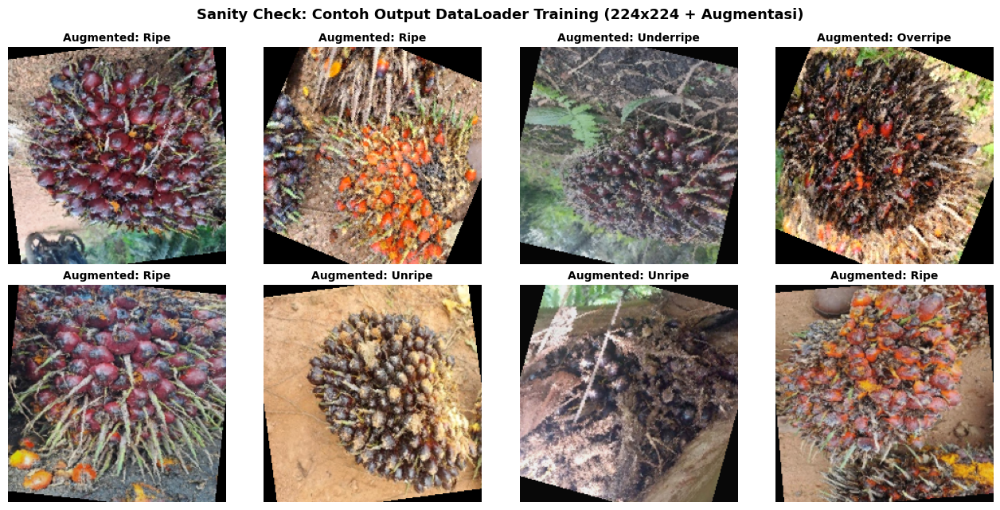

In [9]:
def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Mengembalikan tensor ternormalisasi ke rentang RGB [0, 1] untuk ditampilkan."""
    tensor = tensor.clone().cpu()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1).permute(1, 2, 0).numpy()

# Ambil 1 batch dari train_loader
images_batch, labels_batch = next(iter(train_loader))
print(f"Shape Tensor Gambar (Batch, Channel, Height, Width): {images_batch.shape}")
print(f"Shape Tensor Label  (Batch,)                        : {labels_batch.shape}")

# Visualisasi 8 gambar pertama hasil augmentasi on-the-fly
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for i, ax in enumerate(axes.flat):
    img_vis = denormalize(images_batch[i])
    label_str = class_names[labels_batch[i].item()]
    ax.imshow(img_vis)
    ax.set_title(f"Augmented: {label_str}", fontsize=10, fontweight="bold")
    ax.axis("off")

plt.suptitle("Sanity Check: Contoh Output DataLoader Training (224x224 + Augmentasi)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Pipeline 4:** Model Architecture Setup & Controlled Training

In [10]:
!pip install -q timm grad-cam

import time
import copy
import timm
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score
)
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Buat folder untuk menyimpan bobot model terbaik (.pth) dan hasil evaluasi (.csv)
OUTPUT_DIR = Path("hasil_eksperimen_sawit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Direktori penyimpanan siap di: {OUTPUT_DIR.resolve()}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Direktori penyimpanan siap di: /content/hasil_eksperimen_sawit


In [11]:
class CustomCNN(nn.Module):
    """Baseline CNN 4-Blok yang dilatih dari nol (tanpa pre-trained weights)."""
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            # Blok 1: 224 -> 112
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2, 2),

            # Blok 2: 112 -> 56
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2, 2),

            # Blok 3: 56 -> 28
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2, 2),

            # Blok 4: 28 -> 14
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2, 2),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=False),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


# Daftar konfigurasi model yang akan dikomparasi
MODEL_CONFIGS = {
    "Custom_CNN_Baseline": {"timm_id": None, "lr": 1e-3},
    "ResNet50":            {"timm_id": "resnet50.a1_in1k", "lr": 2e-4},
    "MobileNetV3_Large":   {"timm_id": "mobilenetv3_large_100.ra_in1k", "lr": 3e-4},
    "DenseNet121":         {"timm_id": "densenet121.ra_in1k", "lr": 2e-4},
    "ConvNeXt_Tiny":       {"timm_id": "convnext_tiny.fb_in22k_ft_in1k", "lr": 1e-4},
}

def build_model(model_name, num_classes=NUM_CLASSES):
    seed_everything(SEED)
    cfg = MODEL_CONFIGS[model_name]
    if cfg["timm_id"] is None:
        model = CustomCNN(num_classes=num_classes)
    else:
        model = timm.create_model(cfg["timm_id"], pretrained=True, num_classes=num_classes)
    return model.to(device)

# Cek jumlah parameter setiap model sebelum training
print(f"{'Nama Model':<22} | {'Total Parameter':>16}")
print("-" * 43)
for name in MODEL_CONFIGS:
    m = build_model(name)
    total_params = sum(p.numel() for p in m.parameters())
    print(f"{name:<22} | {total_params:>16,}")
    del m
torch.cuda.empty_cache()

Nama Model             |  Total Parameter
-------------------------------------------
Custom_CNN_Baseline    |          422,788


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

ResNet50               |       23,516,228


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

DenseNet121            |        6,957,956


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

ConvNeXt_Tiny          |       27,823,204


In [12]:
EPOCHS = 20
PATIENCE = 5  # Early stopping jika Val F1 tidak membaik selama 5 epoch

# Gunakan class_weights_tensor hasil perhitungan EDA di Cell 3
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

def train_and_evaluate_model(model_name, epochs=EPOCHS, patience=PATIENCE):
    print(f"\n{'='*65}")
    print(f"MEMULAI TRAINING MODEL: {model_name}")
    print(f"{'='*65}")

    model = build_model(model_name, NUM_CLASSES)
    lr = MODEL_CONFIGS[model_name]["lr"]
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [],  "val_acc": [],
        "val_f1": [],     "epoch_time": []
    }

    best_val_f1 = 0.0
    best_epoch = 0
    no_improve_count = 0
    best_model_path = OUTPUT_DIR / f"best_{model_name}.pth"

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        # --- FASE TRAINING ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct_train += (preds == labels).sum().item()
            total_train += labels.size(0)

        scheduler.step()
        train_loss = running_loss / total_train
        train_acc = correct_train / total_train

        # --- FASE VALIDASI ---
        model.eval()
        val_running_loss = 0.0
        val_preds_all = []
        val_labels_all = []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)
                preds = outputs.argmax(dim=1)
                val_preds_all.extend(preds.cpu().numpy())
                val_labels_all.extend(labels.cpu().numpy())

        val_loss = val_running_loss / len(val_dataset)
        val_acc = accuracy_score(val_labels_all, val_preds_all)
        _, _, val_f1, _ = precision_recall_fscore_support(
            val_labels_all, val_preds_all, average="macro", zero_division=0
        )
        elapsed = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
        history["epoch_time"].append(elapsed)

        # Simpan checkpoint model terbaik berdasarkan Macro F1-Score
        marker = ""
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            no_improve_count = 0
            torch.save(model.state_dict(), best_model_path)
            marker = "  <-- [Saved Best]"
        else:
            no_improve_count += 1

        print(
            f"Epoch [{epoch:02d}/{epochs:02d}] ({elapsed:4.1f}s) | "
            f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:5.2f}% | "
            f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:5.2f}% F1: {val_f1:.4f}{marker}"
        )

        if no_improve_count >= patience:
            print(f"--> Early stopping aktif pada epoch {epoch} (Best Epoch: {best_epoch}, Best Val F1: {best_val_f1:.4f})")
            break

    # Simpan log training ke CSV
    df_hist = pd.DataFrame(history)
    df_hist.to_csv(OUTPUT_DIR / f"history_{model_name}.csv", index_label="epoch")

    del model
    torch.cuda.empty_cache()
    return history

# Jalankan eksperimen untuk seluruh model
all_histories = {}
for model_name in MODEL_CONFIGS.keys():
    all_histories[model_name] = train_and_evaluate_model(model_name)


MEMULAI TRAINING MODEL: Custom_CNN_Baseline
Epoch [01/20] (37.4s) | Train Loss: 1.1070 Acc: 50.47% | Val Loss: 0.9082 Acc: 61.80% F1: 0.6138  <-- [Saved Best]
Epoch [02/20] (29.5s) | Train Loss: 0.8669 Acc: 62.23% | Val Loss: 0.8380 Acc: 66.38% F1: 0.6552  <-- [Saved Best]
Epoch [03/20] (29.5s) | Train Loss: 0.7980 Acc: 65.69% | Val Loss: 0.8125 Acc: 66.95% F1: 0.6689  <-- [Saved Best]
Epoch [04/20] (29.6s) | Train Loss: 0.7148 Acc: 69.20% | Val Loss: 0.7850 Acc: 68.43% F1: 0.6728  <-- [Saved Best]
Epoch [05/20] (29.6s) | Train Loss: 0.6761 Acc: 72.59% | Val Loss: 0.7452 Acc: 70.05% F1: 0.6974  <-- [Saved Best]
Epoch [06/20] (30.4s) | Train Loss: 0.6729 Acc: 71.95% | Val Loss: 0.6388 Acc: 74.63% F1: 0.7394  <-- [Saved Best]
Epoch [07/20] (29.6s) | Train Loss: 0.6147 Acc: 76.57% | Val Loss: 0.5928 Acc: 77.10% F1: 0.7689  <-- [Saved Best]
Epoch [08/20] (29.7s) | Train Loss: 0.6152 Acc: 74.53% | Val Loss: 0.5947 Acc: 77.03% F1: 0.7647
Epoch [09/20] (29.7s) | Train Loss: 0.5715 Acc: 76.23

**Pipeline 5:** Quantitative Evaluation, Metrics Report & Computational Benchmark

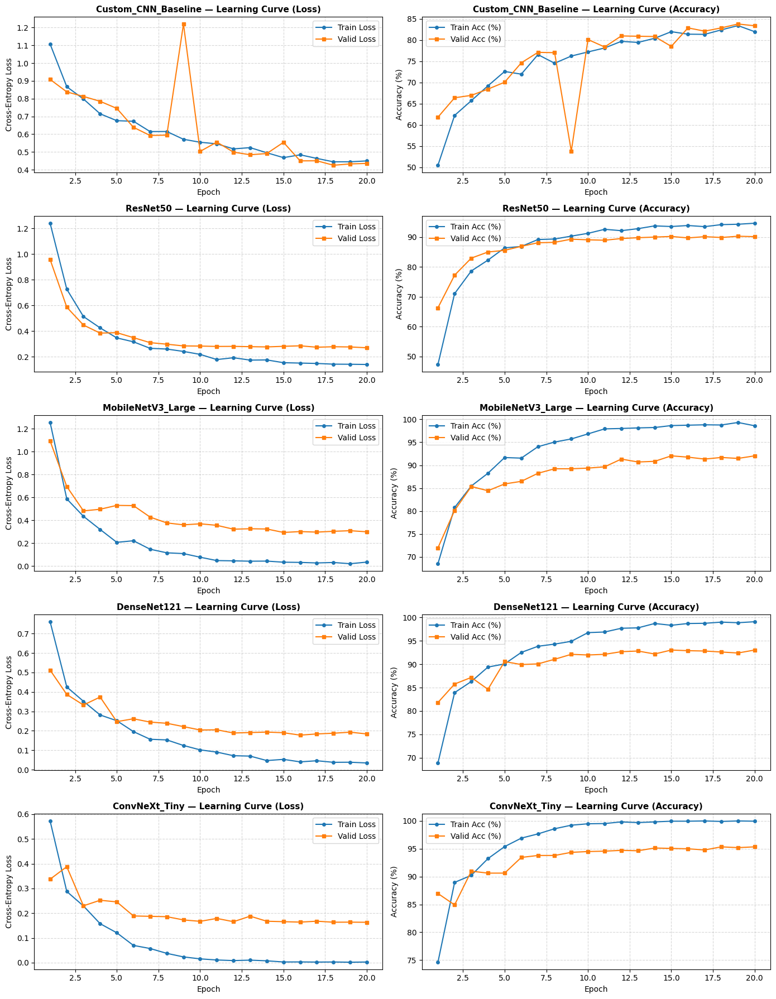

In [13]:
fig, axes = plt.subplots(len(MODEL_CONFIGS), 2, figsize=(14, 3.6 * len(MODEL_CONFIGS)))

for idx, (model_name, hist) in enumerate(all_histories.items()):
    epochs_range = range(1, len(hist["train_loss"]) + 1)

    # Plot Loss
    ax_loss = axes[idx, 0]
    ax_loss.plot(epochs_range, hist["train_loss"], label="Train Loss", marker="o", markersize=4)
    ax_loss.plot(epochs_range, hist["val_loss"], label="Valid Loss", marker="s", markersize=4)
    ax_loss.set_title(f"{model_name} — Learning Curve (Loss)", fontsize=11, fontweight="bold")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Cross-Entropy Loss")
    ax_loss.grid(True, linestyle="--", alpha=0.5)
    ax_loss.legend()

    # Plot Accuracy
    ax_acc = axes[idx, 1]
    ax_acc.plot(epochs_range, [a * 100 for a in hist["train_acc"]], label="Train Acc (%)", marker="o", markersize=4)
    ax_acc.plot(epochs_range, [a * 100 for a in hist["val_acc"]], label="Valid Acc (%)", marker="s", markersize=4)
    ax_acc.set_title(f"{model_name} — Learning Curve (Accuracy)", fontsize=11, fontweight="bold")
    ax_acc.set_xlabel("Epoch")
    ax_acc.set_ylabel("Accuracy (%)")
    ax_acc.grid(True, linestyle="--", alpha=0.5)
    ax_acc.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curves_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


CLASSIFICATION REPORT (TEST SET) — Custom_CNN_Baseline
              precision    recall  f1-score   support

    Overripe     0.8565    0.9062    0.8807       224
        Ripe     0.8543    0.7404    0.7932       285
   Underripe     0.7702    0.7987    0.7842       298
      Unripe     0.8146    0.8978    0.8542       137

    accuracy                         0.8210       944
   macro avg     0.8239    0.8358    0.8281       944
weighted avg     0.8225    0.8210    0.8200       944


CLASSIFICATION REPORT (TEST SET) — ResNet50
              precision    recall  f1-score   support

    Overripe     0.8852    0.9643    0.9231       224
        Ripe     0.8809    0.8561    0.8683       285
   Underripe     0.8865    0.8389    0.8621       298
      Unripe     0.9504    0.9781    0.9640       137

    accuracy                         0.8941       944
   macro avg     0.9007    0.9094    0.9044       944
weighted avg     0.8938    0.8941    0.8932       944


CLASSIFICATION REPORT (TEST 

,Model,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Weighted F1,ROC-AUC (OvR),Params (M),Size (MB),Train (s/epoch),Infer (ms/img)
0,ConvNeXt_Tiny,94.60,0.9486,0.9511,0.9498,0.9459,0.9938,27.82,106.21,68.5,6.99
1,DenseNet121,92.16,0.9284,0.9311,0.9296,0.9214,0.9881,6.96,27.13,38.0,7.09
2,MobileNetV3_Large,91.95,0.9248,0.9282,0.9264,0.9193,0.9872,4.21,16.25,30.6,6.75
3,ResNet50,89.41,0.9007,0.9094,0.9044,0.8932,0.9819,23.52,90.01,39.1,8.29
4,Custom_CNN_Baseline,82.10,0.8239,0.8358,0.8281,0.8200,0.9613,0.42,1.63,30.0,11.91


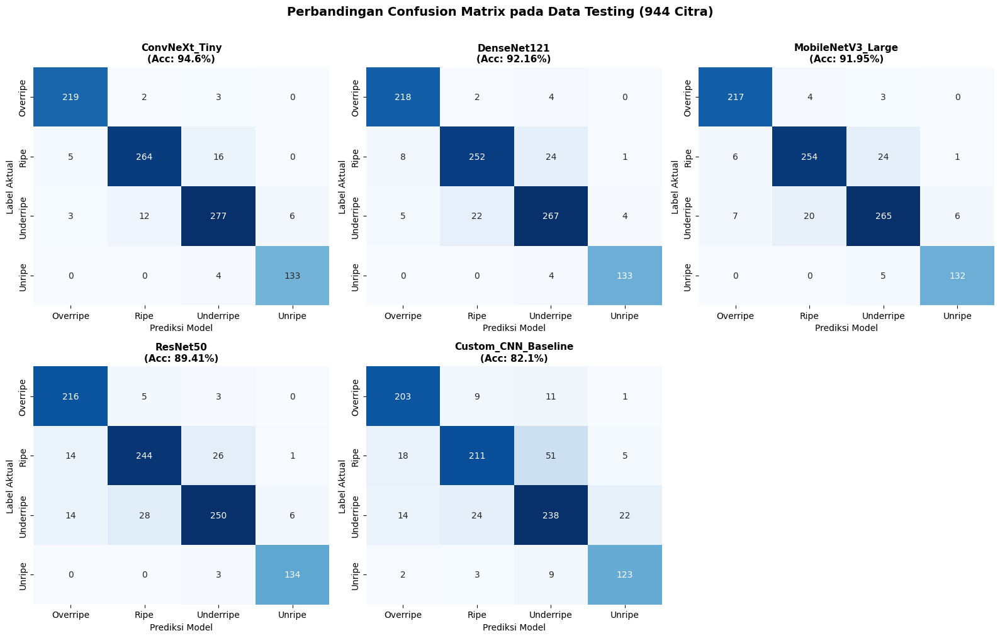

In [14]:
test_results = {}
summary_rows = []

for model_name in MODEL_CONFIGS.keys():
    model = build_model(model_name, NUM_CLASSES)
    weight_path = OUTPUT_DIR / f"best_{model_name}.pth"
    model.load_state_dict(torch.load(weight_path, map_location=device))
    model.eval()

    all_preds = []
    all_probs = []
    all_labels = []

    # Warm-up GPU sebelum mengukur waktu inferensi
    dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
    with torch.no_grad():
        _ = model(dummy_input)

    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.time()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    torch.cuda.synchronize() if torch.cuda.is_available() else None
    total_infer_time = time.time() - t0
    ms_per_image = (total_infer_time / len(test_dataset)) * 1000

    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="weighted", zero_division=0
    )
    roc_auc = roc_auc_score(all_labels, all_probs, multi_class="ovr", average="macro")

    total_params = sum(p.numel() for p in model.parameters())
    model_size_mb = weight_path.stat().st_size / (1024 * 1024)
    avg_epoch_sec = np.mean(all_histories[model_name]["epoch_time"])

    test_results[model_name] = {
        "labels": all_labels,
        "preds": all_preds,
        "probs": all_probs,
        "macro_f1": macro_f1
    }

    summary_rows.append({
        "Model": model_name,
        "Test Accuracy (%)": round(acc * 100, 2),
        "Macro Precision": round(macro_p, 4),
        "Macro Recall": round(macro_r, 4),
        "Macro F1-Score": round(macro_f1, 4),
        "Weighted F1": round(weighted_f1, 4),
        "ROC-AUC (OvR)": round(roc_auc, 4),
        "Params (M)": round(total_params / 1e6, 2),
        "Size (MB)": round(model_size_mb, 2),
        "Train (s/epoch)": round(avg_epoch_sec, 1),
        "Infer (ms/img)": round(ms_per_image, 2)
    })

    print(f"\n{'='*65}")
    print(f"CLASSIFICATION REPORT (TEST SET) — {model_name}")
    print(f"{'='*65}")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    del model
    torch.cuda.empty_cache()

# 1. Tampilkan & Simpan Tabel Rekap Komparasi Akhir
df_summary = pd.DataFrame(summary_rows).sort_values(by="Macro F1-Score", ascending=False).reset_index(drop=True)
df_summary.to_csv(OUTPUT_DIR / "final_model_comparison.csv", index=False)
print("\nTABEL KOMPARASI AKHIR SELURUH MODEL (DIURUTKAN BERDASARKAN MACRO F1-SCORE):")
display(df_summary)

# 2. Plot Confusion Matrix untuk Seluruh Model
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.flat

for idx, model_name in enumerate(df_summary["Model"]):
    ax = axes_flat[idx]
    cm = confusion_matrix(test_results[model_name]["labels"], test_results[model_name]["preds"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names, ax=ax, cbar=False
    )
    ax.set_title(f"{model_name}\n(Acc: {df_summary.loc[idx, 'Test Accuracy (%)']}%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Prediksi Model")
    ax.set_ylabel("Label Aktual")

# Sembunyikan subplot ke-6 yang kosong
axes_flat[-1].axis("off")

plt.suptitle("Perbandingan Confusion Matrix pada Data Testing (944 Citra)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Pipeline 6:** Explainable AI (XAI) Visualization dengan Grad-CAM

Ditemukan 21 gambar sesuai filter (menampilkan 8 pertama):


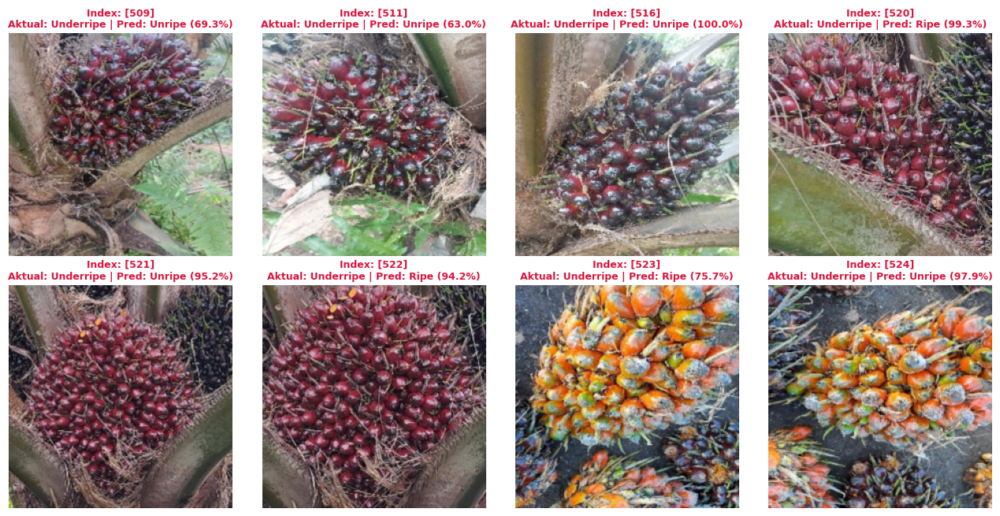

In [17]:
def get_target_layers(model, model_name):
    """Mengambil layer konvolusi terakhir yang optimal untuk setiap arsitektur."""
    if model_name == "Custom_CNN_Baseline":
        return [model.features[-2]]
    elif model_name == "ResNet50":
        return [model.layer4[-1]]
    elif model_name == "MobileNetV3_Large":
        return [model.blocks[-1][-1]]
    elif model_name == "DenseNet121":
        return [model.features.norm5]
    elif model_name == "ConvNeXt_Tiny":
        return [model.stages[-1].blocks[-1]]
    else:
        raise ValueError(f"Nama model '{model_name}' tidak dikenali.")

def load_trained_model(model_name):
    """Memuat arsitektur beserta bobot terbaik yang sudah disimpan."""
    model = build_model(model_name, NUM_CLASSES)
    weight_path = OUTPUT_DIR / f"best_{model_name}.pth"
    model.load_state_dict(torch.load(weight_path, map_location=device))
    model.eval()
    return model

def browse_test_samples(model_name, filter_true_class=None, only_errors=False, max_show=12):
    """
    Menampilkan grid thumbnail beserta nomor indeks (ds_idx) dari test_dataset
    agar Anda bisa mencatat nomor indeks gambar yang ingin dipilih manual.
    """
    y_true = test_results[model_name]["labels"]
    y_pred = test_results[model_name]["preds"]
    y_prob = test_results[model_name]["probs"]

    candidate_idxs = np.arange(len(test_dataset))

    if filter_true_class is not None:
        target_c = class_to_idx[filter_true_class]
        candidate_idxs = candidate_idxs[y_true[candidate_idxs] == target_c]

    if only_errors:
        candidate_idxs = candidate_idxs[y_true[candidate_idxs] != y_pred[candidate_idxs]]

    print(f"Ditemukan {len(candidate_idxs)} gambar sesuai filter (menampilkan {min(max_show, len(candidate_idxs))} pertama):")
    shown_idxs = candidate_idxs[:max_show]

    if len(shown_idxs) == 0:
        return

    cols = 4
    rows = int(np.ceil(len(shown_idxs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.3 * rows))
    axes_flat = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes_flat):
        if i < len(shown_idxs):
            ds_idx = shown_idxs[i]
            img_tensor, true_lbl = test_dataset[ds_idx]
            pred_lbl = y_pred[ds_idx]
            conf = y_prob[ds_idx, pred_lbl] * 100
            color = "darkgreen" if true_lbl == pred_lbl else "crimson"

            ax.imshow(denormalize(img_tensor))
            ax.set_title(
                f"Index: [{ds_idx}]\nAktual: {class_names[true_lbl]} | Pred: {class_names[pred_lbl]} ({conf:.1f}%)",
                fontsize=9, fontweight="bold", color=color
            )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

browse_test_samples(model_name="ConvNeXt_Tiny", filter_true_class="Underripe", only_errors=True, max_show=8)

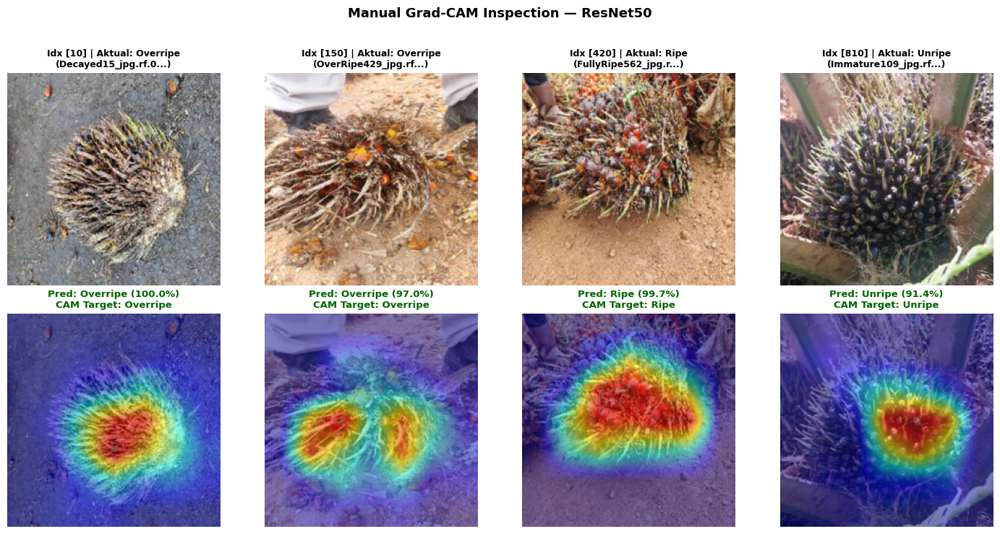

In [18]:
def plot_manual_gradcam(model_name, sample_indices, target_class_name=None, save_filename=None):
    model = load_trained_model(model_name)
    cam = GradCAM(model=model, target_layers=get_target_layers(model, model_name))

    n_samples = len(sample_indices)
    fig, axes = plt.subplots(2, n_samples, figsize=(3.6 * n_samples, 7.2))
    if n_samples == 1:
        axes = axes.reshape(2, 1)

    for col, ds_idx in enumerate(sample_indices):
        img_tensor, true_lbl = test_dataset[ds_idx]
        filepath, _ = test_dataset.samples[ds_idx]
        input_tensor = img_tensor.unsqueeze(0).to(device)

        with torch.no_grad():
            probs = torch.softmax(model(input_tensor), dim=1)[0].cpu().numpy()
        pred_lbl = int(np.argmax(probs))
        conf = probs[pred_lbl] * 100

        # Tentukan kelas target untuk heatmap Grad-CAM
        cam_target_idx = pred_lbl if target_class_name is None else class_to_idx[target_class_name]
        grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(cam_target_idx)])[0]

        rgb_img = denormalize(img_tensor).astype(np.float32)
        cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Baris atas: Citra Asli
        axes[0, col].imshow(rgb_img)
        axes[0, col].set_title(
            f"Idx [{ds_idx}] | Aktual: {class_names[true_lbl]}\n({Path(filepath).name[:18]}...)",
            fontsize=9, fontweight="bold"
        )
        axes[0, col].axis("off")

        # Baris bawah: Grad-CAM Overlay
        status_color = "darkgreen" if true_lbl == pred_lbl else "crimson"
        axes[1, col].imshow(cam_overlay)
        axes[1, col].set_title(
            f"Pred: {class_names[pred_lbl]} ({conf:.1f}%)\nCAM Target: {class_names[cam_target_idx]}",
            fontsize=9.5, fontweight="bold", color=status_color
        )
        axes[1, col].axis("off")

    plt.suptitle(f"Manual Grad-CAM Inspection — {model_name}", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    if save_filename:
        plt.savefig(OUTPUT_DIR / save_filename, dpi=200, bbox_inches="tight")
    plt.show()

    del model
    torch.cuda.empty_cache()

# ==============================================================================
# Pilihan model: "Custom_CNN_Baseline", "ResNet50", "MobileNetV3_Large", "DenseNet121", "ConvNeXt_Tiny"
# ==============================================================================
PILIH_MODEL = "ResNet50"
PILIH_INDEKS_GAMBAR = [10, 150, 420, 810]  # Ganti dengan indeks test_dataset (0 - 943)

plot_manual_gradcam(
    model_name=PILIH_MODEL,
    sample_indices=PILIH_INDEKS_GAMBAR,
    target_class_name=None,
    save_filename=f"gradcam_manual_{PILIH_MODEL}.png"
)

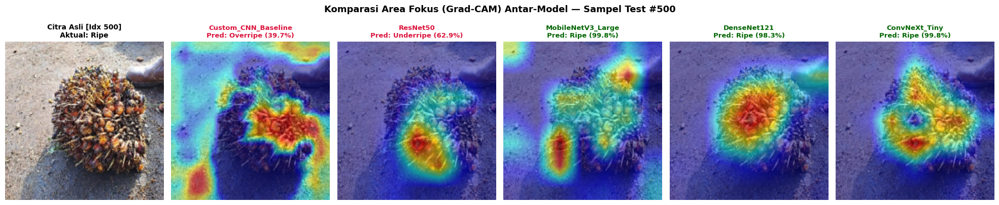

In [21]:
def compare_all_models_gradcam(ds_idx, save_filename=None):
    """Membandingkan Grad-CAM seluruh model pada 1 citra uji yang sama."""
    model_list = list(MODEL_CONFIGS.keys())
    total_cols = len(model_list) + 1  # 1 kolom gambar asli + 5 kolom model

    img_tensor, true_lbl = test_dataset[ds_idx]
    input_tensor = img_tensor.unsqueeze(0).to(device)
    rgb_img = denormalize(img_tensor).astype(np.float32)

    fig, axes = plt.subplots(1, total_cols, figsize=(3.3 * total_cols, 4.0))

    # Kolom 0: Gambar Asli
    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Citra Asli [Idx {ds_idx}]\nAktual: {class_names[true_lbl]}", fontsize=10, fontweight="bold")
    axes[0].axis("off")

    # Kolom 1..5: Grad-CAM masing-masing model
    for idx, model_name in enumerate(model_list, start=1):
        model = load_trained_model(model_name)
        cam = GradCAM(model=model, target_layers=get_target_layers(model, model_name))

        with torch.no_grad():
            probs = torch.softmax(model(input_tensor), dim=1)[0].cpu().numpy()
        pred_lbl = int(np.argmax(probs))
        conf = probs[pred_lbl] * 100

        grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(pred_lbl)])[0]
        cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        status_color = "darkgreen" if true_lbl == pred_lbl else "crimson"
        axes[idx].imshow(cam_overlay)
        axes[idx].set_title(
            f"{model_name}\nPred: {class_names[pred_lbl]} ({conf:.1f}%)",
            fontsize=9.5, fontweight="bold", color=status_color
        )
        axes[idx].axis("off")

        del model
        torch.cuda.empty_cache()

    plt.suptitle(f"Komparasi Area Fokus (Grad-CAM) Antar-Model — Sampel Test #{ds_idx}", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout()
    if save_filename:
        plt.savefig(OUTPUT_DIR / save_filename, dpi=200, bbox_inches="tight")
    plt.show()

# Contoh: Bandingkan ke-5 model pada sampel uji indeks ke-250
compare_all_models_gradcam(ds_idx=500, save_filename="gradcam_all_models_idx250.png")

TABEL KOMPARASI PERFORMA VS BEBAN KOMPUTASI:


,Model,Test Acc (%),Macro F1,Params (M),GFLOPs,Size (MB),Peak VRAM (MB),Train (s/epoch),Total Train (min),Latency (ms/img),Throughput (FPS)
0,ConvNeXt_Tiny,94.60,0.9498,27.80,8.91,106.21,470.7,68.5,22.84,6.32,158.3
1,DenseNet121,92.16,0.9296,6.87,5.67,27.13,385.5,38.0,12.66,15.94,62.7
2,MobileNetV3_Large,91.95,0.9264,4.18,0.43,16.25,399.7,30.6,10.21,6.50,153.8
3,ResNet50,89.41,0.9044,23.52,8.26,90.01,492.2,39.1,13.02,6.01,166.3
4,Custom_CNN_Baseline,82.10,0.8281,0.42,1.50,1.63,480.2,30.0,10.01,0.79,1260.3




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



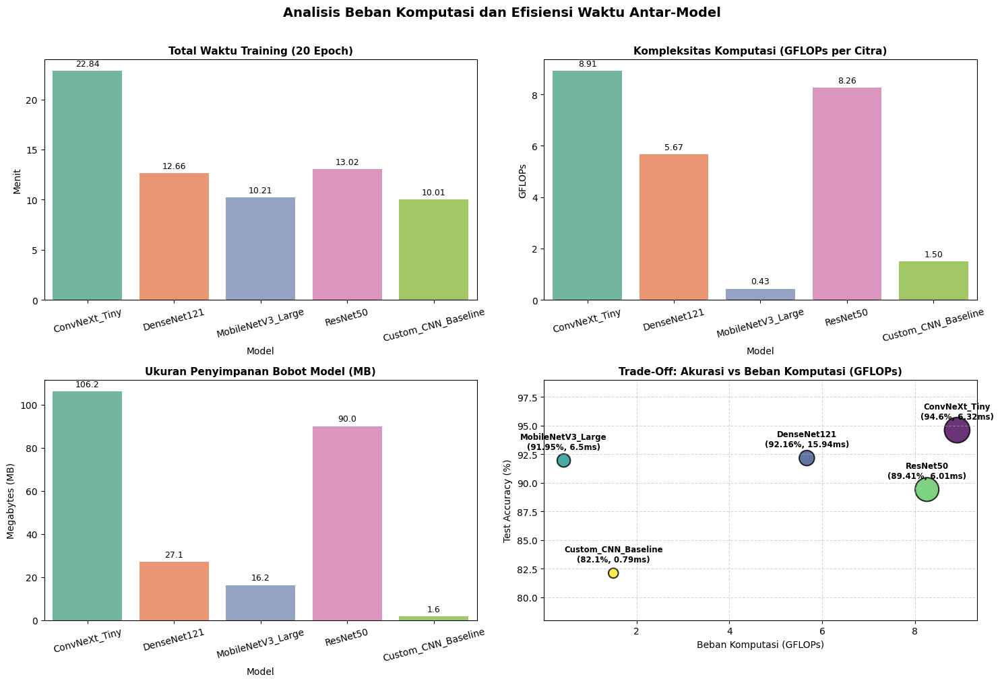

In [22]:
!pip install -q thop

from thop import profile

benchmark_rows = []
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)

for model_name in df_summary["Model"]:
    model = build_model(model_name, NUM_CLASSES)
    weight_path = OUTPUT_DIR / f"best_{model_name}.pth"
    model.load_state_dict(torch.load(weight_path, map_location=device))
    model.eval()

    # 1. Hitung GFLOPs dan Jumlah Parameter
    macs, params = profile(model, inputs=(dummy_input,), verbose=False)
    gflops = (macs * 2) / 1e9  # 1 MAC = 2 FLOPs
    params_m = params / 1e6
    size_mb = weight_path.stat().st_size / (1024 * 1024)

    # 2. Ukur Peak VRAM (MB) saat inferensi
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        with torch.no_grad():
            _ = model(dummy_input)
        torch.cuda.synchronize()
        peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 * 1024)
    else:
        peak_vram_mb = 0.0

    # 3. Ukur Pure GPU Latency (ms/gambar) & FPS (100 iterasi setelah warm-up)
    for _ in range(15):  # Warm-up
        with torch.no_grad():
            _ = model(dummy_input)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_start = time.time()
    n_runs = 100
    with torch.no_grad():
        for _ in range(n_runs):
            _ = model(dummy_input)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    pure_latency_ms = ((time.time() - t_start) / n_runs) * 1000
    fps = 1000.0 / pure_latency_ms

    # 4. Ambil data waktu training dari all_histories
    epoch_times = all_histories[model_name]["epoch_time"]
    avg_sec_epoch = np.mean(epoch_times)
    total_train_min = np.sum(epoch_times) / 60.0
    test_acc = df_summary.loc[df_summary["Model"] == model_name, "Test Accuracy (%)"].values[0]
    macro_f1 = df_summary.loc[df_summary["Model"] == model_name, "Macro F1-Score"].values[0]

    benchmark_rows.append({
        "Model": model_name,
        "Test Acc (%)": test_acc,
        "Macro F1": macro_f1,
        "Params (M)": round(params_m, 2),
        "GFLOPs": round(gflops, 2),
        "Size (MB)": round(size_mb, 2),
        "Peak VRAM (MB)": round(peak_vram_mb, 1),
        "Train (s/epoch)": round(avg_sec_epoch, 1),
        "Total Train (min)": round(total_train_min, 2),
        "Latency (ms/img)": round(pure_latency_ms, 2),
        "Throughput (FPS)": round(fps, 1)
    })

    del model
    torch.cuda.empty_cache()

df_compute = pd.DataFrame(benchmark_rows)
df_compute.to_csv(OUTPUT_DIR / "computational_benchmark.csv", index=False)
print("TABEL KOMPARASI PERFORMA VS BEBAN KOMPUTASI:")
display(df_compute)

# Visualisasi 4-Panel: Beban Komputasi, Waktu & Trade-off Efisiensi
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
palette = sns.color_palette("Set2", len(df_compute))

# Panel 1: Total Waktu Training (Menit)
sns.barplot(data=df_compute, x="Model", y="Total Train (min)", palette=palette, ax=axes[0, 0])
axes[0, 0].set_title("Total Waktu Training (20 Epoch)", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Menit")
axes[0, 0].tick_params(axis="x", rotation=15)
for c in axes[0, 0].containers:
    axes[0, 0].bar_label(c, fmt="%.2f", padding=3, fontsize=9)

# Panel 2: Beban Komputasi (GFLOPs)
sns.barplot(data=df_compute, x="Model", y="GFLOPs", palette=palette, ax=axes[0, 1])
axes[0, 1].set_title("Kompleksitas Komputasi (GFLOPs per Citra)", fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("GFLOPs")
axes[0, 1].tick_params(axis="x", rotation=15)
for c in axes[0, 1].containers:
    axes[0, 1].bar_label(c, fmt="%.2f", padding=3, fontsize=9)

# Panel 3: Ukuran Model (MB)
sns.barplot(data=df_compute, x="Model", y="Size (MB)", palette=palette, ax=axes[1, 0])
axes[1, 0].set_title("Ukuran Penyimpanan Bobot Model (MB)", fontsize=11, fontweight="bold")
axes[1, 0].set_ylabel("Megabytes (MB)")
axes[1, 0].tick_params(axis="x", rotation=15)
for c in axes[1, 0].containers:
    axes[1, 0].bar_label(c, fmt="%.1f", padding=3, fontsize=9)

# Panel 4: Trade-off Scatter Plot (GFLOPs vs Test Accuracy, ukuran bubble = Size MB)
ax_sc = axes[1, 1]
scatter = ax_sc.scatter(
    df_compute["GFLOPs"],
    df_compute["Test Acc (%)"],
    s=df_compute["Size (MB)"] * 6 + 100,
    c=range(len(df_compute)),
    cmap="viridis",
    alpha=0.8,
    edgecolors="black",
    linewidth=1.5
)
for _, row in df_compute.iterrows():
    ax_sc.annotate(
        f"{row['Model']}\n({row['Test Acc (%)']}%, {row['Latency (ms/img)']}ms)",
        (row["GFLOPs"], row["Test Acc (%)"]),
        textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8.5, fontweight="bold"
    )
ax_sc.set_title("Trade-Off: Akurasi vs Beban Komputasi (GFLOPs)", fontsize=11, fontweight="bold")
ax_sc.set_xlabel("Beban Komputasi (GFLOPs)")
ax_sc.set_ylabel("Test Accuracy (%)")
ax_sc.set_ylim(78, 99)
ax_sc.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Analisis Beban Komputasi dan Efisiensi Waktu Antar-Model", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "computational_comparison.png", dpi=200, bbox_inches="tight")
plt.show()